# Our 3 baseline Strategies
- Buy and Hold the Stock
- Momentum - Whats rising will keep rising and whats falling will keep falling
- Reversion - Market tends to return to its original state

In [154]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ipynb.fs.full.data import returns

In [155]:
nifty_index=pd.read_csv('nifty_index.csv')

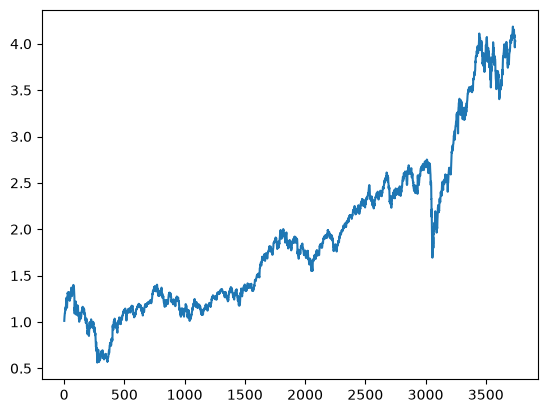

In [156]:
# BUY AND HOLD
train_data=0.8*len(nifty_index)
daily_returns=returns(nifty_index)[:int(train_data)]
starting = 1
buy_and_hold_returns=starting*(1+daily_returns).cumprod()
plt.plot(buy_and_hold_returns)


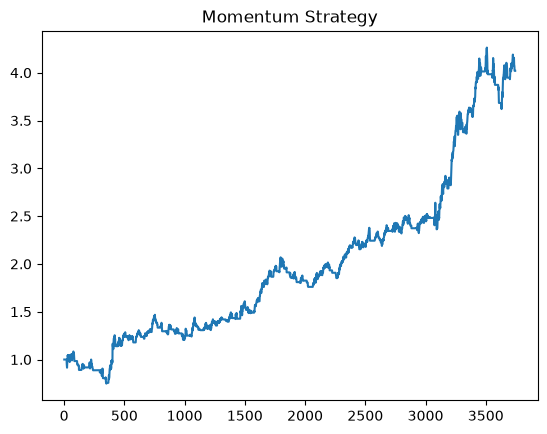

In [157]:
# Momentum Strat
# If for last 20 days, cummulative return is positive, hold, else cash


cumulative_returns = (1 + daily_returns).rolling(20).apply(np.prod, raw=True) - 1

signal = (cumulative_returns > 0).astype(int).shift(1).fillna(0)

momentum_returns = signal * daily_returns

momentum_portfolio = (1 + momentum_returns).cumprod()

plt.plot(momentum_portfolio)
plt.title("Momentum Strategy")
plt.show()

In [158]:
train_size = int(0.8 * len(nifty_index))
train_index = nifty_index.iloc[:train_size].copy()

daily_returns = returns(train_index)
price = train_index["Close"]

price_average = price.rolling(20).mean()
price_std_dev = price.rolling(20).std()

price_zscore = (price - price_average) / price_std_dev

signal = (price_zscore < -1.5).astype(int).shift(1).fillna(0)

mean_reversion_returns = signal * daily_returns
mean_reversion_portfolio = (1 + mean_reversion_returns).cumprod()

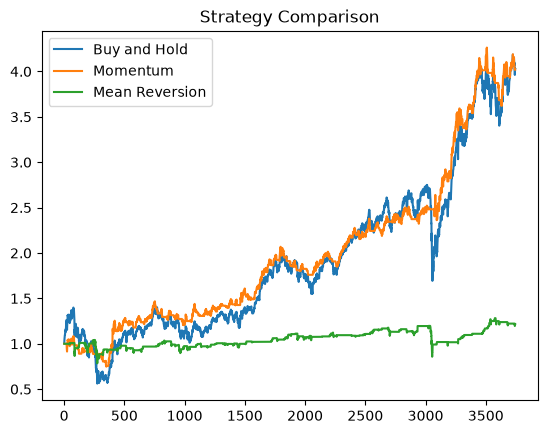

In [159]:
buy_and_hold = (1 + daily_returns).cumprod()

plt.plot(buy_and_hold, label="Buy and Hold")
plt.plot(momentum_portfolio, label="Momentum")
plt.plot(mean_reversion_portfolio, label="Mean Reversion")
plt.legend()
plt.title("Strategy Comparison")
plt.show()

In [161]:
print(len(buy_and_hold))
print(len(momentum_portfolio))
print(len(mean_reversion_portfolio))

print(buy_and_hold.index.equals(momentum_portfolio.index))
print(buy_and_hold.index.equals(mean_reversion_portfolio.index))

3745
3745
3745
True
True
